## Environment Test Notes
- Verified Ubuntu successfully imports the required tools: pyBigWig and pybedtools
- Windows failed at this and hence I had to switch to Ubuntu.

In [1]:
import pyBigWig
import pybedtools 

print("pyBigWig version:", pyBigWig.__version__) 
print("pybedtools version:", pybedtools.__version__)

pyBigWig version: 0.3.24
pybedtools version: 0.12.1


## TP53 Binding Peaks (BED File)
- pybedtools is used to load the BED file containing TP53 binding peaks. 
- Through the len function we can determine the total number of peaks.
- **File used** : "GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed"

In [2]:
import pybedtools 
peaks = pybedtools.BedTool("GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed")

print(peaks.head())
print("Total peaks:" , len(peaks))

chr1	181134909	181135386	.	1000	.	1282.74570	-1.00000	2.70501	237	5.000000	5.000000	181134924	181135373	654.08118	221	181134923	181135363	619.14670	221
 chr11	65422804	65423662	.	1000	.	1110.60869	-1.00000	2.70501	267	5.000000	5.000000	65422819	65423578	568.61494	252	65422816	65423549	529.32633	276
 chr9	115944087	115944510	.	1000	.	1081.92662	-1.00000	2.70501	231	5.000000	5.000000	115944120	115944488	557.74089	167	115944149	115944485	523.50319	174
 chr17	59842914	59844140	.	1000	.	919.85648	-1.00000	2.70501	832	5.000000	5.000000	59842959	59844112	437.94863	819	59842959	59844100	462.83414	785
 chr17	43360918	43361355	.	1000	.	792.85706	-1.00000	2.70501	238	5.000000	5.000000	43360970	43361320	359.66172	144	43360968	43361333	436.80560	211
 chr8	29770484	29770782	.	1000	.	707.27033	-1.00000	2.70501	156	5.000000	5.000000	29770499	29770768	387.63311	146	29770507	29770747	320.24424	133
 chr17	43315892	43316232	.	1000	.	667.17380	-1.00000	2.70501	176	5.000000	5.000000	43315929	43316218	340.79

## BigWig for Signal tracking 
- pyBigWig function is used to open the signal track file 
- **file name**: "GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig'
- through pyBigWig we can extract the signal values for each peak: this is the signal intensity value which represents how strong the experimental signal is at each position. signal itensity can also be interpreted as the binding strength. Hence, we are mapping a quantitative binding strength to the genomic coordinates. We are finding how strongly TP53 binds at each site. 

In [3]:
bw = pyBigWig.open("GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig")

print(bw.chroms()) #shows the chromosomes with data

# example: extract signal values for the first peak 
first_peak = peaks[0] #a tp53 binding site 
vals = bw.values(first_peak.chrom, first_peak.start, first_peak.end)
print("Signal values for first peak:", vals[:10])

bw.close()

{'chr1': 248956422, 'chr10': 133797422, 'chr11': 135086622, 'chr11_KI270721v1_random': 100316, 'chr12': 133275309, 'chr13': 114364328, 'chr14': 107043718, 'chr14_GL000009v2_random': 201709, 'chr14_GL000194v1_random': 191469, 'chr14_GL000225v1_random': 211173, 'chr14_KI270722v1_random': 194050, 'chr14_KI270723v1_random': 38115, 'chr14_KI270724v1_random': 39555, 'chr14_KI270725v1_random': 172810, 'chr14_KI270726v1_random': 43739, 'chr15': 101991189, 'chr15_KI270727v1_random': 448248, 'chr16': 90338345, 'chr16_KI270728v1_random': 1872759, 'chr17': 83257441, 'chr17_GL000205v2_random': 185591, 'chr17_KI270729v1_random': 280839, 'chr17_KI270730v1_random': 112551, 'chr18': 80373285, 'chr19': 58617616, 'chr1_KI270706v1_random': 175055, 'chr1_KI270707v1_random': 32032, 'chr1_KI270708v1_random': 127682, 'chr1_KI270709v1_random': 66860, 'chr1_KI270710v1_random': 40176, 'chr1_KI270711v1_random': 42210, 'chr1_KI270712v1_random': 176043, 'chr1_KI270713v1_random': 40745, 'chr1_KI270714v1_random': 417

## RNA SEQ count matrix 
Preprocess the data:
- remove empty columns while fixing missing values
- some gene symbols appears more than once, so groupby is used to merge these rows into one row per gene symbol: we have a RNA-seq matrix where each row represents a **gene** and each columns is a **sample**.
- what groupby does? it tells pandas to group the rows with the same gene ID and sum their counts, hence we have only a single row for that geneID in the matrix. 
- print the shape and sample names to check the matrix. 

In [4]:
import pandas as pd

# load the RNA SEQ count matrix 
counts = pd.read_csv("GSE274604_count.txt", sep="\t", index_col=0)

# remove empty columns and merge duplicate entries 
counts = counts.dropna(axis=1, how="all")        
counts = counts.groupby(level=0).sum()  

# Check 
print("Clean shape:", counts.shape)
print("Samples:", list(counts.columns))
counts.head()

Clean shape: (43424, 8)
Samples: ['WT_Ctrl_DMSO', 'WT_Ctrl_DOXO', 'WT_AMO_DMSO', 'WT_AMO_DOXO', 'MT_Ctrl_DMSO', 'MT_Ctrl_DOXO', 'MT_AMO_DMSO', 'MT_AMO_DOXO']


,WT_Ctrl_DMSO,WT_Ctrl_DOXO,WT_AMO_DMSO,WT_AMO_DOXO,MT_Ctrl_DMSO,MT_Ctrl_DOXO,MT_AMO_DMSO,MT_AMO_DOXO
Gene Symbol,,,,,,,,
A1BG,177,237,263,197,222,302,192,198
A1BG-AS1,2,4,7,18,10,6,4,3
A1CF,1,2,0,1,1,0,0,0
A2M,4,3,9,4,9,0,7,4
A2M-AS1,1,0,6,0,1,2,2,4


## TP53 Motif matrix: PFM - PWM
- PFM is the raw nucleotide counts at each position in the motif:
- consensus sequence is the most frequest base at each position
- normalize PFM to PWM: couts are converted to probabilities for each base at each position. 

In [5]:
# PFM directly 

from Bio import motifs

with open("MA0106.1.pfm") as handle:
    motif_records = motifs.parse(handle, "jaspar")

motif_list = list(motif_records)
tp53_motif = motif_list[0]

print("Consensus sequence:", tp53_motif.consensus)
print("Counts matrix:\n", tp53_motif.counts)

# Convert to PWM
pwm = tp53_motif.counts.normalize(pseudocounts=0.5)
print("PWM matrix:\n", pwm)


Consensus sequence: CCGGACATGCCCGGGCATGT
Counts matrix:
         0      1      2      3      4      5      6      7      8      9     10     11     12     13     14     15     16     17     18     19
A:   5.00   3.00   4.00   5.00  13.00   0.00  17.00   0.00   0.00   0.00   0.00   0.00   1.00   1.00   4.00   1.00  15.00   2.00   1.00   1.00
C:   8.00   7.00   0.00   0.00   0.00  17.00   0.00   0.00   0.00  11.00  16.00  16.00   0.00   0.00   0.00  14.00   0.00   0.00   1.00   2.00
G:   2.00   6.00  13.00  12.00   4.00   0.00   0.00   0.00  17.00   0.00   0.00   0.00  15.00  14.00  13.00   2.00   0.00   0.00  14.00   1.00
T:   2.00   1.00   0.00   0.00   0.00   0.00   0.00  17.00   0.00   6.00   1.00   1.00   1.00   2.00   0.00   0.00   2.00  15.00   1.00  13.00

PWM matrix:
         0      1      2      3      4      5      6      7      8      9     10     11     12     13     14     15     16     17     18     19
A:   0.29   0.18   0.24   0.29   0.71   0.03   0.92   0.03   0.03   0.0

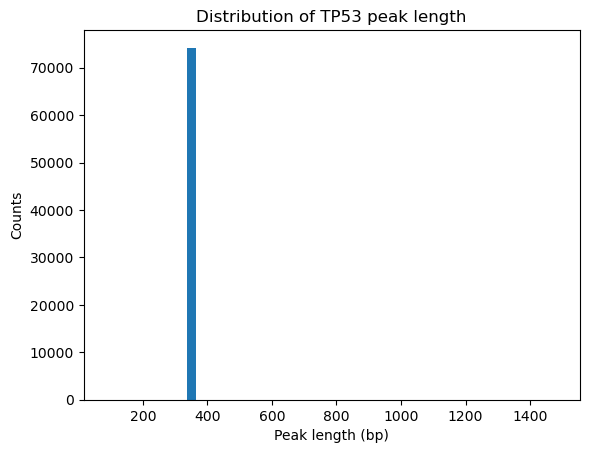

In [6]:
lengths = [p.length for p in peaks]
import matplotlib.pyplot as plt 
plt.hist(lengths, bins=50)
plt.xlabel("Peak length (bp)")
plt.ylabel("Counts")
plt.title("Distribution of TP53 peak length")
plt.savefig("images/01_peak_length.png", dpi=150, bbox_inches="tight")
plt.show()



## Signal Intensity Distribution: 
- analyzing the distribution of the TP53 binding signal intensities from the BigWig track
- extract signal values for the first 1000 peaks
- visualize the binding strength of the signal across peaks
- identify where binding strength is clustering
- if there is high signal then there is strong binding evidemce
- note: the file is sorted by signal, so the first 1000 peaks are the strongest ones and not a radnom sample. 

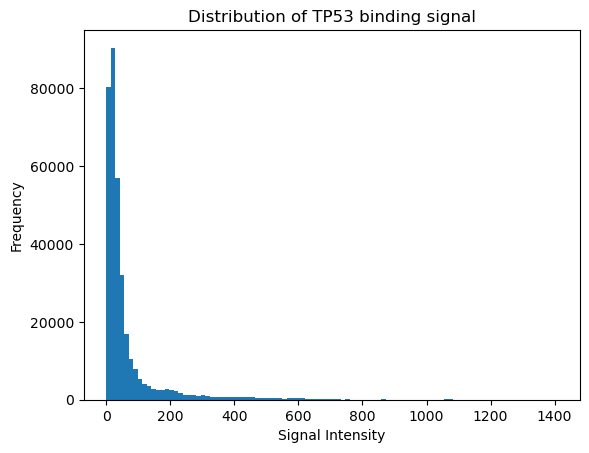

In [7]:
bw = pyBigWig.open("GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig")
import numpy as np
vals = []
for p in peaks[:1000]:
    vals.extend(bw.values(p.chrom, p.start, p.end))
        
plt.hist(np.array(vals), bins=100)
plt.xlabel("Signal Intensity")
plt.ylabel("Frequency")
plt.title("Distribution of TP53 binding signal")
plt.savefig("images/02_signal_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

<Axes: >

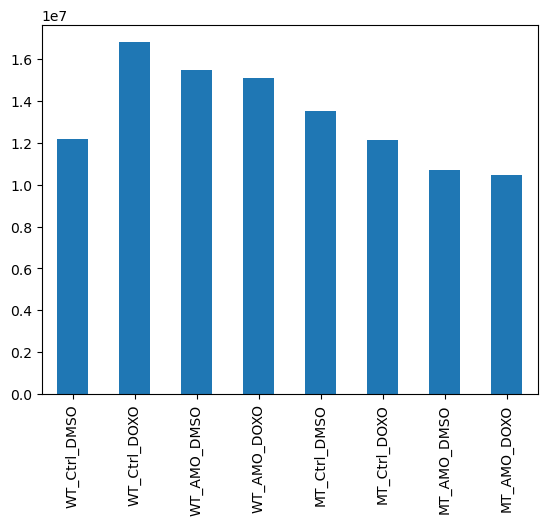

In [8]:
# RNA seq count 
counts.sum(axis=0).plot(kind="bar")

In [9]:
# Validate the motif from JASPAR matches 
# TP53s expected binding pattern before applying enrichment analysis
print("Consensus:", tp53_motif.consensus)

Consensus: CCGGACATGCCCGGGCATGT


## Annotate Peaks to Genes 
- we intersect the BED file and the GTF file
- use pybedtools to filter the GTF entries for genes
- find the closest gene to each peak
- extract the specific gene_id, gene_name and distance
- this way we can connect binding sites to the nearby genes 

In [10]:
# INPUT FILES 
BED_FILE = "GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed"
GTF_FILE = "gencode.v38.annotation.gtf"
OUTPUT_FILE = "TP53_peak_gene_map.tsv"

def annotate_peaks_to_genes(bed_file, gtf_file, output_file):
    peaks = pybedtools.BedTool(bed_file)

    gtf = pybedtools.BedTool(gtf_file)

    genes = gtf.filter(lambda x: x[2] == "gene").saveas() #keep only gene entries 

    closest = peaks.sort().closest(genes.sort(), d=True) #find nearest gene for each peak 

    # write results to the output file  
    with open(output_file, "w") as out:
        out.write("peak_chr\tpeak_start\tpeak_end\tgene_id\tgene_name\tdistance\n")
        for entry in closest:
            peak_chr, peak_start, peak_end = entry[0], entry[1], entry[2]

            gene_id, gene_name = "NA", "NA"
            #extract gene attributes from GTF and calculate distance between peak and gene
            if len(entry) > 9 and ";" in entry[-2]:
                attrs = {kv.split()[0]: kv.split()[1].strip('"')
                         for kv in entry[-2].split(";")
                         if kv.strip() and len(kv.split()) > 1}
                gene_id = attrs.get("gene_id", "NA")
                gene_name = attrs.get("gene_name", "NA")

            distance = entry[-1]
            #write results to TSV file 
            out.write(f"{peak_chr}\t{peak_start}\t{peak_end}\t{gene_id}\t{gene_name}\t{distance}\n")
            
    print(f"[INFO] Annotation complete. Results saved to {output_file}")

if __name__ == "__main__":
    annotate_peaks_to_genes(BED_FILE, GTF_FILE, OUTPUT_FILE)



[INFO] Annotation complete. Results saved to TP53_peak_gene_map.tsv


## Average Intensity Signal for every ChIP-seq peak 
- input the BED ad BigWig file for the peaks and signal track
- by summarizing data abotu signals per peak we can calculate the quantified binding strength, compare peaks and integrate gene annotations with the RNA seq. 

In [11]:


BED_FILE = "GSE176658_ENCFF041VRQ_IDR_ranked_peaks_GRCh38.bed"
BIGWIG_FILE = "GSE176658_ENCFF608GZS_signal_p-value_GRCh38.bigWig"
OUTPUT_FILE = "TP53_peak_signal.tsv"

def summarise_peak_signals(bed_file, bigwig_file, output_file):
    peaks = pybedtools.BedTool(bed_file)
    bw = pyBigWig.open(bigwig_file)

    with open(output_file, "w") as out:
        out.write("peak_chr\tpeak_start\tpeak_end\tmean_signal\n")

        # iterate through each peak in the BED file 
        for peak in peaks:
            # extract signal values across the peak region
            vals = bw.values(peak.chrom, peak.start, peak.end, numpy=True)

            # compute the average signal intensity
            mean_signal = np.nanmean(vals) if vals is not None else 0 

            # write the peak coordinates and the mean signal to output file 
            out.write(f"{peak.chrom}\t{peak.start}\t{peak.end}\t{mean_signal:.4f}\n")

    bw.close()
    print(f"[INFO] Signal summarization complete. Results saved to {output_file}")

if __name__ == "__main__":
    summarise_peak_signals(BED_FILE, BIGWIG_FILE, OUTPUT_FILE) 

[INFO] Signal summarization complete. Results saved to TP53_peak_signal.tsv


## Purpose is to load, clean, filter and normalize the RNA-seq count data 
- produced a normalized count matrix for downstream analysis 

In [12]:
import pandas as pd 
COUNT_FILE = "GSE274604_count.txt"

counts = pd.read_csv(COUNT_FILE, sep="\t", index_col = 0)
counts = counts.dropna(axis=1, how="all")
print("[INFO] Raw counts shape:", counts.shape)
print(counts.shape)

# filter genes with total counts < 10 across all samples 
filtered = counts[counts.sum(axis = 1) >= 10]
print("\n[INFO] After filtering: ", filtered.shape)

# normalize counts 
import numpy as np 

# compute geomteric means 
geometric_means = np.exp(np.log(filtered+1).mean(axis=1))

# ratios and size factors 
ratios = filtered.div(geometric_means, axis = 0)
size_factors = ratios.median(axis=0)

# save nornalised counts 
normalized = filtered.div(size_factors, axis=1)
OUTPUT_FILE = "RNAseq_normalized_counts.tsv"
normalized.to_csv(OUTPUT_FILE, sep="\t")
print(f"\n[INFO] Noralized counts saved to {OUTPUT_FILE}")



[INFO] Raw counts shape: (43424, 8)
(43424, 8)

[INFO] After filtering:  (20688, 8)

[INFO] Noralized counts saved to RNAseq_normalized_counts.tsv


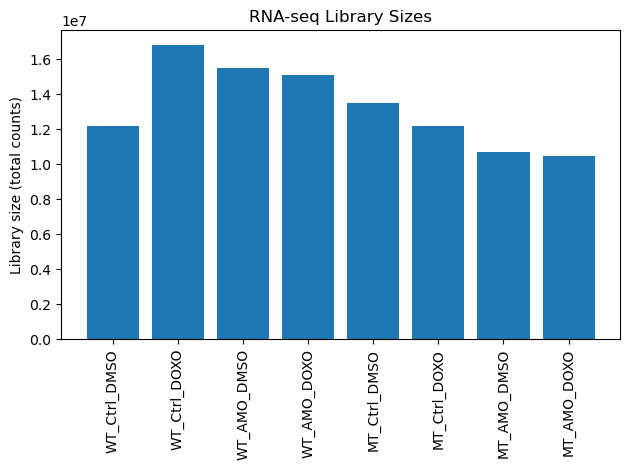

In [13]:
lib_sizes = counts.sum(axis=0)
plt.bar(lib_sizes.index, lib_sizes.values)
plt.xticks(rotation=90)
plt.ylabel("Library size (total counts)")
plt.title("RNA-seq Library Sizes")
plt.tight_layout()
plt.savefig("images/03_library_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
import sklearn
print(sklearn.__version__)
import numpy as np

1.7.2


## Principal Component Analysis
- reduce the dimensionality of large datasets while preserving the variation as much as possible
- applied log transform to stabilize the variance and reduce skews from highly expressed genes 
- Transpose: PCA is run on the samples and not the genes(rows)


(20688, 8)
0
(20688, 8)


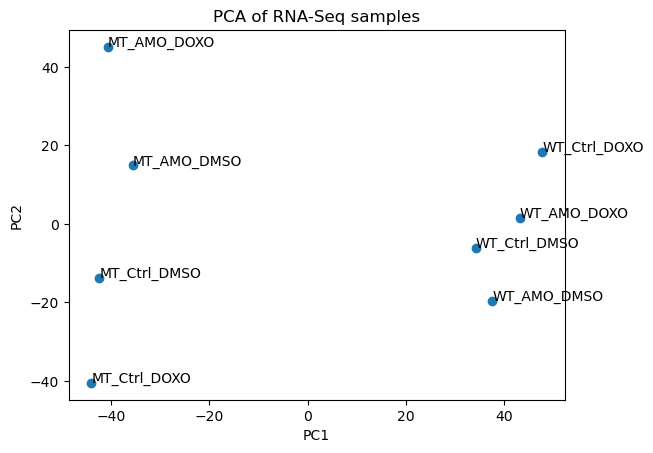

[INFO] PCA coordinates saved to RNAseq_PCA_coordinates.tsv


In [15]:
print(normalized.shape)
print(normalized.isna().sum().sum())   # total NaNs

normalized_clean = normalized.fillna(0)
print(normalized_clean.shape)

normalized_clean = normalized_clean.apply(pd.to_numeric, errors="coerce").fillna(0)

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(np.log1p(normalized_clean.T))

plt.scatter(pcs[:,0], pcs[:,1])
for i, sample in enumerate(normalized_clean.columns):
    plt.text(pcs[i,0], pcs[i,1], sample)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of RNA-Seq samples")
plt.savefig("images/04_pca.png", dpi=150, bbox_inches="tight")
plt.show()

# Save PCA coordinates
pca_df = pd.DataFrame(pcs, index=normalized_clean.columns, columns=["PC1", "PC2"])
pca_df.to_csv("RNAseq_PCA_coordinates.tsv", sep="\t")
print("[INFO] PCA coordinates saved to RNAseq_PCA_coordinates.tsv")


In [16]:
# Check the first 10 lines of the motif file
with open("TP53.meme") as f:
    for i in range(10):
        print(f.readline().strip())


MEME version 4

ALPHABET= ACGT

strands: + -

Background letter frequencies
A 0.25 C 0.25 G 0.25 T 0.25

MOTIF MA0106.3 TP53


In [17]:
! head TP53.meme
!ls fimo_out 
!cat fimo_out/fimo.log

MEME version 4

ALPHABET= ACGT

strands: + -

Background letter frequencies
A 0.25 C 0.25 G 0.25 T 0.25

MOTIF MA0106.3 TP53
best_site.narrowPeak  cisml.xml	 fimo.gff  fimo.html  fimo.tsv	fimo.xml
cat: fimo_out/fimo.log: No such file or directory


In [18]:
import pandas as pd

# filtering at p < 1e-6 reduces false positives but does not remove them 

fimo_results = pd.read_csv("fimo_out/fimo.tsv", sep="\t", comment="#")
significant_hits = fimo_results[fimo_results["p-value"] < 1e-6]
significant_hits.to_csv("TP53_motif_hits.tsv", sep="\t", index=False)
print(f"[INFO] {len(significant_hits)} Significant TP53 motif hits saved to TP53_motif_hits.tsv")

[INFO] 5029 Significant TP53 motif hits saved to TP53_motif_hits.tsv


In [19]:
print(significant_hits.shape)
significant_hits.head(10)


(5029, 10)


,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence
0,MA0106.3,TP53,15,62262777,62262794,-,27.5102,1.450000e-10,0.134,GACATGCCCAGGCATGTC
1,MA0106.3,TP53,15,62262777,62262794,-,27.5102,1.450000e-10,0.134,GACATGCCCAGGCATGTC
2,MA0106.3,TP53,8,102236840,102236857,-,27.5102,1.450000e-10,0.134,GACATGCCCAGGCATGTC
3,MA0106.3,TP53,17,39046876,39046893,+,27.4286,1.690000e-10,0.134,AACATGCCCAGGCATGTC
4,MA0106.3,TP53,15,62262777,62262794,+,27.2245,2.250000e-10,0.134,GACATGCCTGGGCATGTC
5,MA0106.3,TP53,15,62262777,62262794,+,27.2245,2.250000e-10,0.134,GACATGCCTGGGCATGTC
6,MA0106.3,TP53,8,102236840,102236857,+,27.2245,2.250000e-10,0.134,GACATGCCTGGGCATGTC
7,MA0106.3,TP53,17,39046876,39046893,-,26.9388,3.170000e-10,0.166,GACATGCCTGGGCATGTT
8,MA0106.3,TP53,4,113561331,113561348,-,25.6939,1.230000e-09,0.536,GGCATGCCCAGGCATGTC
9,MA0106.3,TP53,8,8362977,8362994,-,25.6122,1.360000e-09,0.536,AGCATGCCCAGGCATGTC


## Count Motifs 
- counts motif hits that occue on each DNA strand (+ and - are the two strands of DNA double helix)
- sequence_name is the chromosome, so the counts show how many motif hits fall on each chromosome  

In [20]:
# count hits per strand 
print(significant_hits['strand'].value_counts())
print(significant_hits['sequence_name'].value_counts().head(10))


strand
-    2540
+    2489
Name: count, dtype: int64
sequence_name
1     454
3     371
2     349
6     291
4     285
11    278
8     277
7     271
5     243
12    235
Name: count, dtype: int64


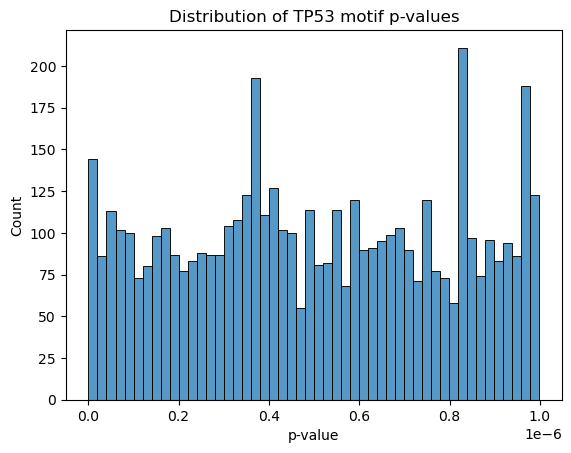

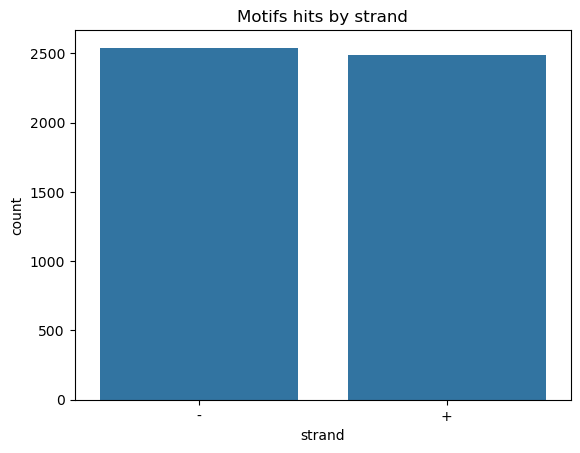

In [21]:
# visualize motif stats 
import matplotlib.pyplot as plt 
import seaborn as sns 

# hist of p values
sns.histplot(significant_hits['p-value'], bins=50)
plt.title("Distribution of TP53 motif p-values")
plt.savefig("images/05_motif_pvalues.png", dpi=150, bbox_inches="tight")
plt.show()

# strand distr
sns.countplot(x='strand', data=significant_hits)
plt.title("Motifs hits by strand")
plt.savefig("images/06_motif_strand.png", dpi=150, bbox_inches="tight")
plt.show()




In [22]:
print(fimo_results.groupby("sequence_name")["stop"].max().head())

sequence_name
1     248849279
10    133660464
11    135006086
12    133145361
13    114300698
Name: stop, dtype: int64


## FIMO motif hits
- Standardize the chromosome names
- ensures all coordinates are numeric and forces them to be numeric
- select significant motif hits with p < 1e-5, sort by score, and remove duplicate sites
- prepare a BED file 

In [23]:
# defining a function to standardise the chromosome names 
def to_chr(x):
    x = str(x)
    # mitochondrial genome --> chrM
    return x if x.startswith("chr") else ("chrM" if x in ("MT", "M") else "chr" + x)

fimo_results = pd.read_csv("fimo_out/fimo.tsv", sep="\t", comment="#").dropna(subset=["start", "stop"])

# map sequence names to standardized chromosome labels
fimo_results["chrom"] = fimo_results["sequence_name"].map(to_chr)

# keep only chromosomes that exist in the BigWig 
valid = set(bw.chroms())
n_dropped = (~fimo_results["chrom"].isin(valid)).sum() #count how many hits are invalid: excluding scaffolds and contigs, files not containing chr
fimo_results = fimo_results[fimo_results["chrom"].isin(valid)]
print(f"Dropped {n_dropped} hits on scaffolds not present in the BigWig")

fimo_results[["start", "stop"]] = fimo_results[["start", "stop"]].astype(int)

# sort by score and remove duplicates
sites = (fimo_results[fimo_results["p-value"] < 1e-5]
         .sort_values("score", ascending=False)
         .drop_duplicates(["chrom", "start", "stop"]))
print(len(sites), "unique motif sites")

# convert site into BED format 
# BED requires a starting coordinate which is 0-based. hence we subtract 1 from the start. 
sites_bed = pybedtools.BedTool.from_dataframe(
    sites.assign(bed_start=sites["start"] - 1)[["chrom", "bed_start", "stop", "matched_sequence", "score", "strand"]]
).sort()

Dropped 21 hits on scaffolds not present in the BigWig
23731 unique motif sites


## which genes have the tp53 binding sites in their promoter regions? 
- extract gene features with gene_id and gene_name
- define promoters
- intersect peaks with promoter to find which genes have tp53 binding site in the promoter region
- count peaks per gene and record the strongest signal
  

In [24]:
import re
rows = []
with open(GTF_FILE) as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        f = line.rstrip("\n").split("\t")
        #keep rows that descrive "gene" features and ignore the exos, transcripts etc
        if len(f) < 9 or f[2] != "gene":
            continue
            #extract gene_id, gene_name 
        gid = re.search(r'gene_id "([^"]+)"', f[8]).group(1)
        gn = re.search(r'gene_name "([^"]+)"', f[8])
        rows.append((f[0], int(f[3]), int(f[4]), f[6], gid, gn.group(1) if gn else gid))

        
genes = pd.DataFrame(rows, columns=["chrom", "start", "end", "strand", "gene_id", "gene_name"])
genes["gene_name"] = genes["gene_name"].str.replace('[;"]', "", regex=True).str.strip()

# compute TSS: it is the start coordinate for + strand, and for - strand it is its the end coordinate 
genes["tss"] = np.where(genes["strand"] == "+", genes["start"] - 1, genes["end"] - 1)

# define promoter regions: 2kb upstream and downstream of TSS
genes["p_start"] = (genes["tss"] - 2000).clip(lower=0)
genes["p_end"] = genes["tss"] + 2000
genes["score"] = 0

# convert promoter data into BED format 
prom_bed = pybedtools.BedTool.from_dataframe(
    genes[["chrom", "p_start", "p_end", "gene_id", "score", "strand"]]).sort()

# intersect peak with promoter regions 
pp = peaks.intersect(prom_bed, wa=True, wb=True).to_dataframe(
    names=[f"p{i}" for i in range(20)] + ["g_chrom", "g_start", "g_end", "gene_id", "g_score", "g_strand"])

pp = pp.rename(columns={"p0": "chrom", "p1": "start", "p2": "end", "p6": "signalValue"})
pp = pp.merge(genes[["gene_id", "gene_name"]], on="gene_id")

# n_peaks number of peaks overlapping promoter 
# max_signal is strongest peak signal in promoter 
bound_genes = (pp.groupby("gene_name")
                 .agg(n_peaks=("start", "size"), max_signal=("signalValue", "max"))
                 .reset_index().sort_values("max_signal", ascending=False))
bound_genes.to_csv("TP53_bound_genes.tsv", sep="\t", index=False)
print("Genes with a TP53 peak in the promoter:", len(bound_genes))
bound_genes.head(10)

Genes with a TP53 peak in the promoter: 16415


,gene_name,n_peaks,max_signal
3905,ENSG10010134742.1,6,1110.60869
3937,ENSG10010136441.1,6,1110.60869
3989,ENSG10010139664.1,6,1110.60869
7976,NEAT1,6,1110.60869
7082,MIR21,7,919.85648
3059,CTD-3014M21.1,2,792.85706
15760,WDR74,3,670.17665
10070,RNU2-2P,3,670.17665
10253,RNVU1-22,3,639.97503
10076,RNU4-1,3,522.85524


In [25]:
print(sorted(sites["chrom"].unique()))
print(sites.groupby("chrom")["stop"].max().head())

['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX', 'chrY']
chrom
chr1     248849279
chr10    133660464
chr11    134484376
chr12    133145361
chr13    114300698
Name: stop, dtype: int64


## Motif enrichment in ChIP-seq peaks  
- define the scanned regions 
- filter the peaks and keep only those which were fully inside the scanned DNA 
- calculate the fraction of obeserved overlap 
- shuffle the peaks 100 times within the same regions and measure motif overlap each time 
- the enrichment test:
    - fold enrichment: observed or random mean 
    - empirical p-value: (1 + number of shuffles with overlap greater than equal to the observed values)/101. with 100 shiffles, the smallest possible value is ~0.0099, so we report it as p<0.01.

In [26]:
# filter out the chromosomes where the motif sites were found 
scanned = sorted(set(sites["chrom"]))

scan_df = pd.read_csv("scanned_regions.bed", sep="\t", header=None, names=["chrom", "start", "end"])
scan_df["chrom"] = scan_df["chrom"].map(to_chr) # standardize chromosome names 
scan_df = scan_df[scan_df["chrom"].isin(scanned)] #filter out only relevant chromosomes 
scan_bed = pybedtools.BedTool.from_dataframe(scan_df).sort()
print("scanned DNA on these chromosomes:", f"{(scan_df['end'] - scan_df['start']).sum():,}", "bases")

# convert peak into BED format 
peaks_bed5 = pybedtools.BedTool.from_dataframe(
    peaks.to_dataframe(usecols=[0, 1, 2, 6], names=["chrom", "start", "end", "signal"])
    .assign(name="peak")[["chrom", "start", "end", "name", "signal"]])

chrom_sizes = bw.chroms()
with open("scanned.genome", "w") as fh:
    for c in scanned:
        fh.write(f"{c}\t{chrom_sizes[c]}\n")

pk_all = peaks_bed5.filter(lambda x: x.chrom in scanned).saveas()

# keep only the peaks which are inside scanned regions where f=1.0 means 100% overlap 
pk = pk_all.intersect(scan_bed, f=1.0, u=True).saveas()      # only peaks fully inside scanned DNA
print(len(pk_all), "peaks on scanned chromosomes ->", len(pk), "fully inside scanned regions")

observed = len(pk.intersect(sites_bed, u=True)) / len(pk)

# shuffle peaks 100 times and measure motif overlap 
shuffled = np.array([len(pk.shuffle(g="scanned.genome", chrom=True, incl=scan_bed.fn, seed=s)
                         .intersect(sites_bed, u=True)) / len(pk) for s in range(100)])

# print the enrichment analysis stats 
print(f"Peaks containing a motif: {observed:.2%} | random regions: {shuffled.mean():.2%} "
      f"| fold = {observed / shuffled.mean():.1f}x | empirical p = {(1 + (shuffled >= observed).sum()) / 101:.3f}")

pd.DataFrame([{"peaks_on_scanned_chromosomes": len(pk_all), "peaks_inside_scanned_regions": len(pk),
               "fraction_with_motif": observed, "fraction_shuffled_mean": shuffled.mean(),
               "fold_enrichment": observed / shuffled.mean(),
               "empirical_p": (1 + (shuffled >= observed).sum()) / 101}]).to_csv("results/motif_in_peaks_all.csv", index=False)

scanned DNA on these chromosomes: 1,807,740,716 bases
74304 peaks on scanned chromosomes -> 57451 fully inside scanned regions
Peaks containing a motif: 0.69% | random regions: 0.47% | fold = 1.5x | empirical p = 0.010


## Test motif enrichment as a function of peak strength 
- checking whether stronger tp53 peaks are more likely to contain the tp53 motifs than weaker ones 
- peaks are sorted by signal or binding strength 
- fold enrichment is when we compare the observed vs random motif overlaps in real peaks vs shuffled peaks 


top   1000 peaks: 4.30% contain a motif vs 0.50% random (8.7x)
top   5000 peaks: 1.82% contain a motif vs 0.48% random (3.8x)
top  20000 peaks: 0.92% contain a motif vs 0.46% random (2.0x)
top  57451 peaks: 0.69% contain a motif vs 0.46% random (1.5x)


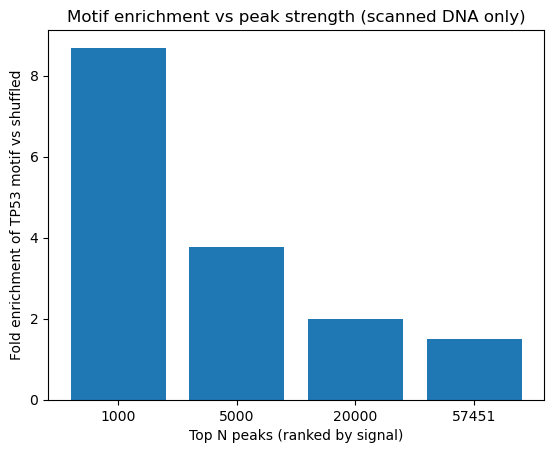

In [27]:
# convert the peaks into a df sorted by strength 
pk_df = pk.to_dataframe(names=["chrom", "start", "end", "name", "signal"]).sort_values("signal", ascending=False)

strength_rows = []

# test enrichment: top 1k, 5k, 20k and at all peaks 
for n in [1000, 5000, 20000, len(pk_df)]:
    # choose the top N strongest peaks 
    top = pybedtools.BedTool.from_dataframe(pk_df.head(n)).sort()

    # calculate the observed fraction of peaks containing a motif 
    obs = len(top.intersect(sites_bed, u=True)) / n

    # the shuffle control uses 20 shiffles per group , versus 100 in the overall test.  
    rnd = np.mean([len(top.shuffle(g="scanned.genome", chrom=True, incl=scan_bed.fn, seed=s)
                       .intersect(sites_bed, u=True)) / n for s in range(20)])
    print(f"top {n:>6} peaks: {obs:.2%} contain a motif vs {rnd:.2%} random ({obs/rnd:.1f}x)")
    strength_rows.append({"top_peaks": n, "fraction_with_motif": obs,
                          "fraction_shuffled": rnd, "fold_enrichment": obs / rnd})
strength_df = pd.DataFrame(strength_rows)
strength_df.to_csv("results/motif_enrichment_by_peak_strength.csv", index=False)

plt.bar([str(n) for n in strength_df["top_peaks"]], strength_df["fold_enrichment"])
plt.xlabel("Top N peaks (ranked by signal)")
plt.ylabel("Fold enrichment of TP53 motif vs shuffled")
plt.title("Motif enrichment vs peak strength (scanned DNA only)")
plt.savefig("images/08_motif_enrichment_by_strength.png", dpi=150, bbox_inches="tight")
plt.show()

## The Doxorubicin (DOXO) treatment affect 
- compute the log2 fold-hange (DOXO vs DMSO) for each condition (WT/MT, plus/minus AMO)
- every gene is split into TP53-bound promoters vs unbound promoter
- for every condition, the distributions of log2FC between bound and unbound genes is compared using the Mann-Whitney U test:
    - instead of assuming normal distribution, it compares whether one group tends to have higher values than the other.
    - often used in distributions with skewed results
      

WT_Ctrl: median log2FC bound = -0.00, unbound = -0.01, p = 0.00015
WT_AMO: median log2FC bound = -0.00, unbound = 0.01, p = 0.31
MT_Ctrl: median log2FC bound = 0.04, unbound = -0.04, p = 8.8e-38
MT_AMO: median log2FC bound = 0.00, unbound = 0.00, p = 0.2


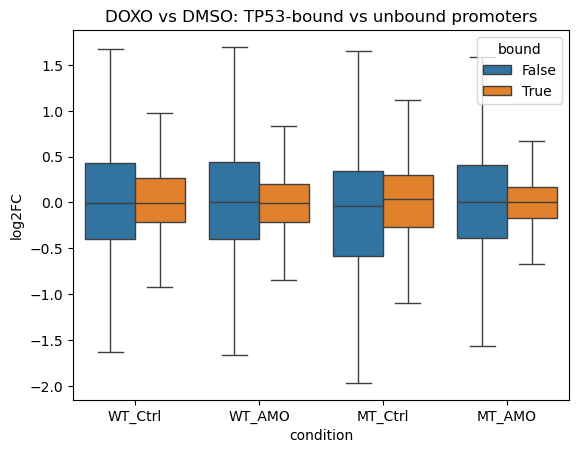

In [28]:
from scipy import stats

# log2 transform normalized counts, add 1 to avoid log(0) 
log2norm = np.log2(normalized + 1)
lfc = pd.DataFrame({
    "WT_Ctrl": log2norm["WT_Ctrl_DOXO"] - log2norm["WT_Ctrl_DMSO"],
    "WT_AMO":  log2norm["WT_AMO_DOXO"]  - log2norm["WT_AMO_DMSO"],
    "MT_Ctrl": log2norm["MT_Ctrl_DOXO"] - log2norm["MT_Ctrl_DMSO"],
    "MT_AMO":  log2norm["MT_AMO_DOXO"]  - log2norm["MT_AMO_DMSO"],
})

# mark whether each gene is tp53 bound 
lfc["bound"] = lfc.index.isin(set(bound_genes["gene_name"]))

bu_rows = []
for cond in ["WT_Ctrl", "WT_AMO", "MT_Ctrl", "MT_AMO"]:
    # split genes into bound and unbound sets 
    b, u = lfc.loc[lfc["bound"], cond], lfc.loc[~lfc["bound"], cond]

    # Mann-Whitney U test: compare distributions of log2FC between boud and unbound genes 
    p = stats.mannwhitneyu(b, u).pvalue
    print(f"{cond}: median log2FC bound = {b.median():.2f}, unbound = {u.median():.2f}, p = {p:.2g}")
    bu_rows.append({"condition": cond, "n_bound": len(b), "n_unbound": len(u),
                    "median_log2FC_bound": round(b.median(), 3),
                    "median_log2FC_unbound": round(u.median(), 3),
                    "mannwhitney_p": p})                       
pd.DataFrame(bu_rows).to_csv("results/bound_vs_unbound_tests.csv", index=False)  
lfc.to_csv("results/log2FC_DOXO_vs_DMSO_all_genes.csv")

sns.boxplot(data=lfc.melt(id_vars="bound", var_name="condition", value_name="log2FC"),
            x="condition", y="log2FC", hue="bound", showfliers=False)
plt.title("DOXO vs DMSO: TP53-bound vs unbound promoters")
plt.savefig("images/07_bound_vs_unbound_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

## Are strongly bound promoters more likely to be induced under DOXO treatment?
- Fisher's Test:
    test whether the induction associated with strong TP53 binding 
- we are asking if there is a significant association between the two variables : strong tp53 binding and DOXO induction 
- it is an exact value which can be considered even with small sample 
- Odds ratio will tell us the strength of the association, and the p-value will tell us whether this association is statistically significant 


In [29]:
from scipy import stats
print("fraction of expressed genes labelled bound:", round(lfc["bound"].mean(), 3))
sig = peaks.to_dataframe(usecols=[6], names=["s"])["s"]
odds_rows = []
for TOP in [2000, 5000]:
    # for the top 2k and 5k peaks, we find the minimum signal threshold, and a gene overlapping a eak greater than this threshold is marked as strong_bound 
    thr = sig.nlargest(TOP).min()
    strong = set(pp.loc[pp["signalValue"] >= thr, "gene_name"])
    lfc["strong_bound"] = lfc.index.isin(strong)

    # for every condition in this list, classify the genes as induced if log2FC greater than equal to 1
    for cond in ["WT_Ctrl", "WT_AMO", "MT_Ctrl", "MT_AMO"]:
        ind = lfc[cond] >= 1
        sb = lfc["strong_bound"]
        table = [[(ind & sb).sum(), (~ind & sb).sum()], [(ind & ~sb).sum(), (~ind & ~sb).sum()]]

        # Fisher's exact test: OR>1 bounds genes are likely to be induced, small p-value means a sigificant statistical association 
        odds, p = stats.fisher_exact(table)
        print(f"top {TOP} peaks | {cond}: induced {table[0][0]}/{sb.sum()} bound vs {table[1][0]}/{(~sb).sum()} unbound | OR={odds:.1f}, p={p:.2g}")
        odds_rows.append({"top_peaks": TOP, "condition": cond,
                          "induced_bound": int(table[0][0]), "n_bound": int(sb.sum()),
                          "induced_unbound": int(table[1][0]), "n_unbound": int((~sb).sum()),
                          "odds_ratio": odds, "p_value": p})     
pd.DataFrame(odds_rows).to_csv("results/strong_binding_vs_induction.csv", index=False)   

fraction of expressed genes labelled bound: 0.472
top 2000 peaks | WT_Ctrl: induced 69/990 bound vs 1799/19698 unbound | OR=0.7, p=0.02
top 2000 peaks | WT_AMO: induced 52/990 bound vs 1734/19698 unbound | OR=0.6, p=4.6e-05
top 2000 peaks | MT_Ctrl: induced 45/990 bound vs 1465/19698 unbound | OR=0.6, p=0.00035
top 2000 peaks | MT_AMO: induced 56/990 bound vs 1876/19698 unbound | OR=0.6, p=1.9e-05
top 5000 peaks | WT_Ctrl: induced 117/2356 bound vs 1751/18332 unbound | OR=0.5, p=6.4e-15
top 5000 peaks | WT_AMO: induced 111/2356 bound vs 1675/18332 unbound | OR=0.5, p=1.6e-14
top 5000 peaks | MT_Ctrl: induced 75/2356 bound vs 1435/18332 unbound | OR=0.4, p=3.3e-19
top 5000 peaks | MT_AMO: induced 110/2356 bound vs 1822/18332 unbound | OR=0.4, p=3.9e-19


## Functional Enrichment Analysis: 
- the analysis is run on genes that have a tp53 peak in their promoter and they are induced by DOXO in the control set. this overlap is the 504 genes. 
- Enrichr is a pathway enrichment test:
    - the enrichr holds hundreds of gene-set libraries. Its limitation is that in the background, it has all genes i each library, not only our expressed genes. 
    - enrichr cross-references our list of genes with its libraries and gene sets. 
    - It then carries out statistical test like Fisher's exact test - prob of intersection between our gene list and its curated gene list. 
    - Results interpretation: if our gene list overlap signficantly with a specific pathway, DNA damage response, enrichr flags it as enriched. Hence suggesting that the biological process is relevant to our experiment. 
- compares our gene list with curated databases to see if certain pathways are over-represented.
- Use Fisher's exact test
- pathways are ranked by significance 

In [30]:
import gseapy as gp
induced = [g for g in lfc.index[(lfc["bound"]) & (lfc["WT_Ctrl"] >= 1)]]

# clean gene names and sort 
induced = sorted(set(pd.Series(induced).str.replace('[;"]', "", regex=True)))
print(len(induced), "TP53-bound genes induced in WT_Ctrl")

# run enrichment analysis using enrichr database
enr = gp.enrichr(gene_list=induced,
                 gene_sets=["MSigDB_Hallmark_2020", "KEGG_2021_Human", "GO_Biological_Process_2023"],
                 organism="human", outdir=None)
print(enr.results.sort_values("Adjusted P-value")[["Gene_set", "Term", "Adjusted P-value"]].head(10))
enr.results.sort_values("Adjusted P-value").to_csv("results/enrichr_bound_induced_WT_Ctrl.csv", index=False)

504 TP53-bound genes induced in WT_Ctrl
                Gene_set                           Term  Adjusted P-value
0   MSigDB_Hallmark_2020                    p53 Pathway      6.381287e-08
1   MSigDB_Hallmark_2020  TNF-alpha Signaling via NF-kB      1.754842e-05
44       KEGG_2021_Human          p53 signaling pathway      3.225642e-03
45       KEGG_2021_Human                     Alcoholism      3.138007e-02
2   MSigDB_Hallmark_2020                Notch Signaling      1.201714e-01
46       KEGG_2021_Human   Systemic lupus erythematosus      1.706753e-01
3   MSigDB_Hallmark_2020                      Apoptosis      2.318195e-01
4   MSigDB_Hallmark_2020          Inflammatory Response      2.702511e-01
47       KEGG_2021_Human              Colorectal cancer      3.420052e-01
49       KEGG_2021_Human                      Apoptosis      3.787290e-01


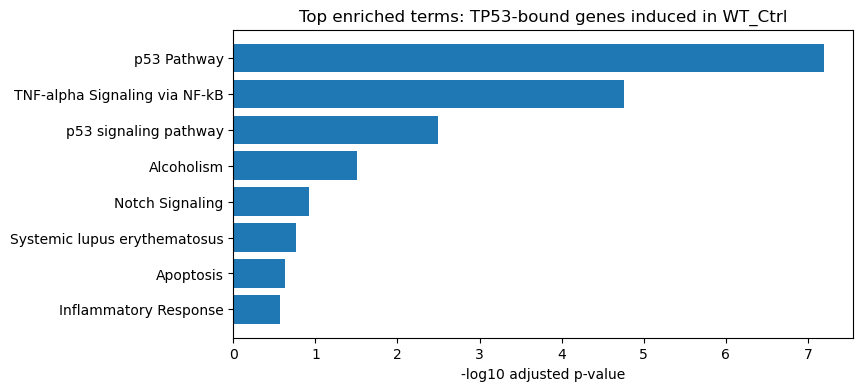

In [31]:
top_terms = enr.results.sort_values("Adjusted P-value").head(8).iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(top_terms["Term"], -np.log10(top_terms["Adjusted P-value"]))
plt.xlabel("-log10 adjusted p-value")
plt.title("Top enriched terms: TP53-bound genes induced in WT_Ctrl")
plt.savefig("images/10_enrichment_top_terms.png", dpi=150, bbox_inches="tight")
plt.show()

## Control Analysis 
- strongly bound genes are much more highly expressed than unbound genes (median of per-gene mean expression about 331 vs 56)
- highly expressed genes find it harder to show a greater than 2 fold increase. this can hide a real association-- it is a confounder.
- so the fisher test is repeated using only genes with mean DMSO expression >= 50 or >= 200.
- after filtering, the Odd ratios rise above 1, but only MT_AMO at mean expression >= 200 is significant. the association therefore is weak and not clearly robust. 

In [32]:
# computes avergae baseline expression for each gene 
lfc["mean_expr"] = normalized[["WT_Ctrl_DMSO","WT_AMO_DMSO","MT_Ctrl_DMSO","MT_AMO_DMSO"]].mean(axis=1).reindex(lfc.index)

# median of each gene's mean DMSO expression, for strongly bound vs unbound genes
# strong_bound here is from the last loop run in the Fisher Cell(top 5k peaks)
med_expr = lfc.groupby("strong_bound")["mean_expr"].median().round(1)
print(med_expr)
med_expr.to_csv("results/median_expression_bound_vs_unbound.csv") 

ctrl_rows=[]

# filter out genes with mean expression greater than 50 or 200. No weakly expressed genes included. 
for MIN in [50, 200]:
    sub = lfc[lfc["mean_expr"] >= MIN]
    sb = sub["strong_bound"]
    for cond in ["WT_Ctrl", "WT_AMO", "MT_Ctrl", "MT_AMO"]:
        ind = sub[cond] >= 1
        table = [[(ind & sb).sum(), (~ind & sb).sum()], [(ind & ~sb).sum(), (~ind & ~sb).sum()]]
        # run fishers test for association 
        odds, p = stats.fisher_exact(table)
        print(f"expr>={MIN} | {cond}: induced {table[0][0]}/{sb.sum()} bound vs {table[1][0]}/{(~sb).sum()} unbound | OR={odds:.2f}, p={p:.2g}")
        ctrl_rows.append({"min_expression": MIN, "condition": cond,
                          "induced_bound": int(table[0][0]), "n_bound": int(sb.sum()),
                          "induced_unbound": int(table[1][0]), "n_unbound": int((~sb).sum()),
                          "odds_ratio": odds, "p_value": p})     
pd.DataFrame(ctrl_rows).to_csv("results/expression_controlled_tests.csv", index=False)  

strong_bound
False     55.8
True     331.2
Name: mean_expr, dtype: float64
expr>=50 | WT_Ctrl: induced 33/1887 bound vs 173/9403 unbound | OR=0.95, p=0.85
expr>=50 | WT_AMO: induced 18/1887 bound vs 76/9403 unbound | OR=1.18, p=0.49
expr>=50 | MT_Ctrl: induced 5/1887 bound vs 28/9403 unbound | OR=0.89, p=1
expr>=50 | MT_AMO: induced 10/1887 bound vs 37/9403 unbound | OR=1.35, p=0.43
expr>=200 | WT_Ctrl: induced 21/1435 bound vs 68/6045 unbound | OR=1.31, p=0.28
expr>=200 | WT_AMO: induced 11/1435 bound vs 23/6045 unbound | OR=2.02, p=0.076
expr>=200 | MT_Ctrl: induced 2/1435 bound vs 6/6045 unbound | OR=1.40, p=0.65
expr>=200 | MT_AMO: induced 6/1435 bound vs 7/6045 unbound | OR=3.62, p=0.025


In [33]:
known = ["CDKN1A","MDM2","BAX","GADD45A","BBC3","PMAIP1","TP53INP1","SESN1","ZMAT3","DDB2","FAS","TNFRSF10B"]
known_tbl = lfc.loc[lfc.index.isin(known), ["WT_Ctrl","WT_AMO","MT_Ctrl","MT_AMO","bound","strong_bound"]].round(2)
known_tbl.to_csv("results/known_p53_targets.csv")                       
known_tbl

,WT_Ctrl,WT_AMO,MT_Ctrl,MT_AMO,bound,strong_bound
Gene Symbol,,,,,,
BAX,0.12,0.71,-0.04,0.50,True,True
BBC3,1.52,1.88,1.41,1.36,True,True
CDKN1A,2.55,2.93,2.37,2.50,True,True
DDB2,0.40,0.49,0.69,0.62,True,True
FAS,1.83,0.68,0.67,0.61,False,False
GADD45A,2.03,2.16,0.16,1.69,True,False
MDM2,1.56,1.57,0.53,1.16,True,True
PMAIP1,1.12,1.06,0.36,0.83,True,False
SESN1,2.14,1.84,0.88,1.10,True,True


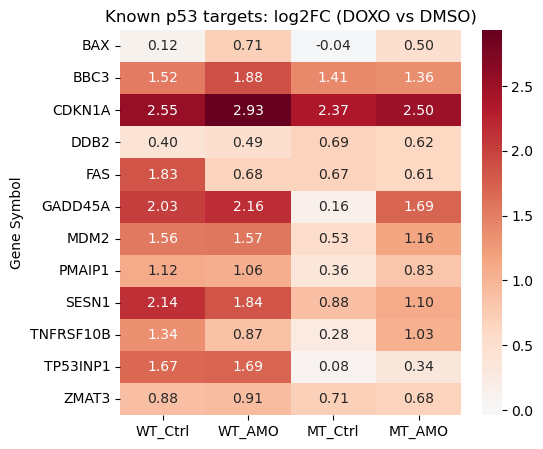

In [34]:
# This helps us validate that the pipeline is capturing the pipeline we have made. 
# known p53 targets should be induced by DOXO in WT cells (e.g, CDKN1A log2FC about 2.5). The 12 targets were chosen from prior knowledge, so this is a sanity check and not independent validation 
plt.figure(figsize=(5.5, 5))
sns.heatmap(known_tbl[["WT_Ctrl","WT_AMO","MT_Ctrl","MT_AMO"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Known p53 targets: log2FC (DOXO vs DMSO)")
plt.savefig("images/09_known_targets_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()